In [6]:
%matplotlib inline
import torch
import random
from d2l import torch as d2l

根据带有噪音的线性模型构造一个人造数据集。我们使用线性模型参数w = 【2，-3.4】、b=4.2和噪音项o生成数据集及其标签
y = Xw+b+o

In [9]:
def synthetic_data(w, b, num_examples):
    X = torch.normal(0, 1, (num_examples, len(w))) # 0 represents the mean, and 1 represents the variance.
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape) # 0.01 is the amount of noise added
    return X, y.reshape((-1, 1))


true_w = torch.tensor([2, -3, 4], dtype=torch.float32)
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)

不用d2l就输入 import matplotlib.pyplot as plt

features中的每一行都包含一个二维数据样本， labels中的每一行都包含一个一维标签值（一个标量）

In [10]:
print('features:', features[0], '\nlabel:', labels[0])

features: tensor([-1.0640,  0.7810,  2.4867]) 
label: tensor([9.6708])


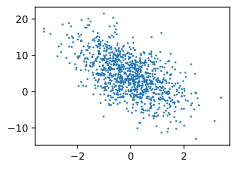

In [12]:
d2l.set_figsize()
d2l.plt.scatter(features[:, 1].detach().numpy(),
                labels.detach().numpy(), 1);

定义一个data——iter函数，该函数接收批量大小、特征矩阵和标签向量作为输入，生成大小为batch_size的小批量

In [42]:
def data_iter(batch_size, features, labels):
    # 1. 获取样本总数
    num_examples = len(features)
    
    # 2. 创建一个包含所有样本索引的列表 [0, 1, 2, ..., num_examples-1]
    indices = list(range(num_examples))
    
    # 3. 随机打乱索引，确保每次epoch读取样本的顺序都不一样，防止模型学到顺序相关的无用特征
    # 注：图片中使用了 random.shuffle 需要提前 import random
    random.shuffle(indices)
    
    # 4. 循环读取数据，步长为 batch_size
    for i in range(0, num_examples, batch_size):
        # 5. 获取当前批次的索引。使用 min() 是为了防止最后一个批次不足 batch_size 时越界
        batch_indices = torch.tensor(
            indices[i:min(i + batch_size, num_examples)])
        
        # 6. 使用 yield 返回当前批次的特征和标签，使函数变成一个生成器（Generator）
        # 这样做的好处是按需生成数据，不需要一次性把所有批次都存在内存里
        yield features[batch_indices], labels[batch_indices]

定义初始化模型参数

In [56]:
w = torch.normal(0, 0.01, size=(3,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)


定义模型

In [50]:
def linreg(X,w,b):
    return torch.matmul(X, w) + b

定义损失函数

In [58]:
def squared_loss(y_hat, y):
    return (y_hat - y.reshape(y_hat.shape))**2 / 2

定义优化函数

In [63]:
def sgd(params, lr, batch_size):
    with torch.no_grad():
        for param in params:
            param -=lr * param.grad / batch_size
            param.grad.zero_()

训练过程

lr是学习率，新参数=旧参数-lr*梯度

In [65]:

lr = 0.03
num_epochs = 3
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for X,y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)
        l.sum().backward()
        sgd([w, b], lr, batch_size)
    with torch.no_grad():
        train_l = loss(net(features,w,b), labels)
        print(f'epoch{epoch + 1}, loss {float(train_l.mean())}')

epoch1, loss 9.38098382903263e-05
epoch2, loss 4.9373062211088836e-05
epoch3, loss 4.937930862070061e-05


比较真实参数和通过训练学到的参数来评估训练的成功程度

In [67]:
print(f'w的估计误差:{true_w-w.reshape(true_w.shape)}')
print(f'b的估计误差：{true_b -b}')

w的估计误差:tensor([-1.5020e-05, -2.4819e-04, -3.4428e-04], grad_fn=<SubBackward0>)
b的估计误差：tensor([-2.0027e-05], grad_fn=<RsubBackward1>)
